# 1. 시계열 데이터
## 1.1 시계열 데이터의 정의
- **시간의 흐름**에 따라 일정한 간격, 순서대로 관측 · 기록된 데이터
- 시계열 데이터 표기 방법
	-  t: 시점(time index) - 1일, 2일, 3일...
	- 𝑌𝑡 : t 시점에 관측된 값
	- T : 마지막 관측 시점

- 시계열 데이터의 조건
	- **시간 순서가 의미를 가진다** : 순서 자체가 정보이기에, 순서를 섞으면 데이터의 의미가 사라짐
	- **관측 간격이 일정하다** : 매초/매시간/매일/매월/매년처럼 간격이 일정해야 시점끼리 비교 가능함. 이 간격을 **주기**라고 함

**단변량 시계열과 다변량 시계열**

- 단변량 시계열 
	- 시간에 따라 **하나의 변수만** 관측한 데이터
	- 오로지 **자기 자신의 과거 값**만보고 미래를 예측
	- 적용 사례
		- 삼성전자의 일별 종가
		- 서울의 일별 평균 온도
		- 한 카페의 일별 아메리카노 판매량

- 다변량 시계열
	- 시간에 따라 **여러 변수를 동시에** 관측한 데이터
	- 자기 자신의 과거뿐 아니라 **다른 변수들의 영향**까지 함께 고려
	- 적용 사례
		- 아메리카노의 판매량 ← 기온 + 강수량 + 요일
		- 전력 사용량 ← 기온 + 습도 + 공휴일 여부
		- 주가 ← 거래량, 환율, 금리

**시계열 분석과 목적**
- 시계열 분석이란? : 시간 순서대로 쌓인 데이터에서 **패턴을 찾아내고**, 이를 바탕으로 **미래 값을 예측**하는 분석 방법
- 시계열 분석의 주 목표: **미래 데이터 예측**
	- 지금까지의 기록을 보고 다음 시점, 그 다음 시점의 값을 추정하는 것
	- 시계열 예측의 기본 가정: **과거의 패턴이 미래에도 어느정도 반복될 것이다**
	- 반대로 말하면, 과거에 없었던 일은 예측하기 어렵다는 한계가 존재

## 1.2 시계열 데이터의 특징
1. 시간의존성
    - 데이터가 시간에 따라 변하고, 현재 시점의 값이 과거 시점의 값에 영향을 받는 성질

    - 특징
        1. 과거의 값이 현재의 값에 영향을 미친다
        2. 보통 가까운 과거일수록 영향이 크다
        3. 순서를 섞으면 안된다.

    => 이런 시간에 따른 변화는 크게 **일정하게 반복되는 모양(계절성)과, 전반적으로 증가하거나 감소하는 모양(추세)**으로 나타난다.

    - 데이터 누수 주의: 시계열 데이터를 랜덤하게 섞으면 미래를 이미 보고 과거를 맞추는 셈이므로 반드시 **과거로 학습하고, 미래로 평가**해야 함

2. 계절성 & 추세
    - 계절성: **일정한 주기(일, 주, 월, 년 등)로 비슷한 패턴**이 반복되는 성질

    - 추세: 시간의 흐름에 따라 데이터가 **장기적으로 증가하거나 감소하는 방향성**
        - 짧게 보면 오르락내리락해도, **멀리서 보면 한 방향**으로 움직이는 흐름

3. 자기상관성
    - 자기상관성: **자기 자신끼리 상관관계를 갖는 특성**
    - 오늘 판매량 vs 어제 판매량처럼 **같은 변수의 현재와 과거를 비교**
    - 개념 및 특징
        - 한 시계열 안에서, 현재 값과 과거 값이 얼마나 비슷하게 움직이는지를 나타내는 정도
        - 시간이 지남에 따라 값들 간에 일정한 패턴이나 반복이 존재
        - 값은 일반 상관계수와 같이 -1~1
        - 시차를 바꿔가며 계산하면 **반복주기(계절성)**을 찾을 수 있음
        - **시차**: 현재 값을 몇 시점 전의 값과 비교하는지
    - **⇒ 한 줄 정리: 자기상관이란 과거 값으로 지금 값을 짐작할 수 있는 정도**

- 자기상관성의 문제점: 회귀분석 불가
    - 회귀분석은 데이터가 서로 독립적이라는 가정 위에서 ① 변수의 영향을 검정하고, ② 변수 간 관계를 찾고, ③ 미래를 예측함
    - 근데 데이터가 자기상관성이 있으면 이 세가지가 모두 흔들림

    1. **오차항 독립성 가정 위반 -> 통계 결과 왜곡**
    - 회귀분석에서는 오차끼리 독립적이라고 가정함
    - 그러나 시계열은 오늘 값이 어제 값을 따라가기 때문에 오차도 어제를 따라감.<br>→ 오차항이 독립적이지 않아 통계적 추론의 왜곡 발생 (검정, 신뢰구간)

    2. **허위 상관관계 문제**
    - 둘 다 시간에 따라 증가/감소하는 시계열이면, 실제로 아무 관계가 없어도 상관관계가 높게 나옴

    3. **예측의 어려움 & 모델 복잡성 증가**
    - 시계열을 분석할 때는 과거와의 관계까지 모델에 넣어야 함
    - 예측 오차가 쌓임
        - 내일을 예측하고, 그 예측값으로 모레를 예측하다 보면, 첫날 조금 틀린게 눈덩이처럼 불어날 위험이 있음
    - 패턴이 바뀔 수 있음

**결론** 
- 시계열 데이터는 시계열 전용 모델을 사용하거나, 사전처리(차분, 추세 제거 등) 후 분석해야 함

## 1.3 시계열 데이터의 분석 요인
- **추세 · 계절 · 순환 · 불규칙**

1. 추세 요인
    - 시계열이 시간 전반에 걸쳐 **증가하거나 감소하는 경향성**을 나타내는 요인
    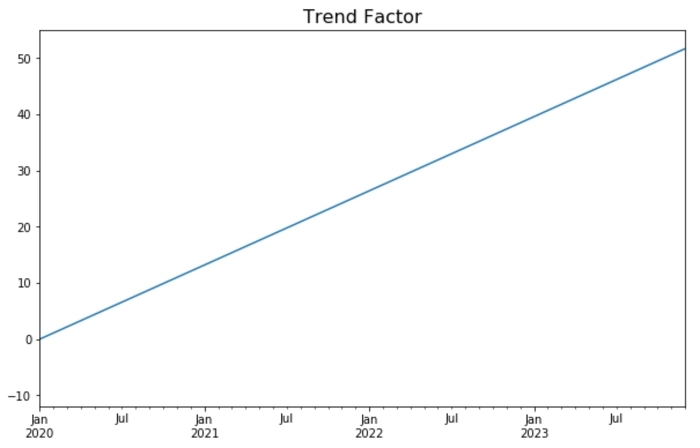
    - 짧은 오르내림은 무시하고 큰 흐름만 본 것
    - 주로 인구 변화, 기술 발전, 물가 상승처럼 오랜 시간에 걸쳐 작용하는 원인 때문에 생김

2. 계절 요인
    - **1년 이내의 일정한 주기로 같은 패턴이 반복되는 요인**
    - 주로 날씨, 달력(요일・공휴일・명절), 사회적 관습처럼 규칙적으로 돌아오는 원인 때문에 생김

3. 순환 요인
    - **계절성보다 더 길고 불규칙한 주기로 반복되는 변동**
    - 보통 1년보다 긴, 몇 년 단위의 움직임이라 긴 기간의 데이터를 봐야 파악할 수 있음.
    - 대표적인 원인: **경기 변동**. 경제는 호황 → 후퇴 → 불황 → 회복을 반복하지만 그 한 바퀴가 3년일 수도, 7년일 수도 있음.

    - 순환요인 주의점
        - 찾아내기 어려움
        - 추세와 구분하기 어려움 -> 추세와 순환을 하나로 묶어 추세 순환 요인으로 부르기도 함.

- 계절성 vs 순환성 구분

    | 구분 | 계절 요인 | 순환 요인 |
    |---|---|---|
    | 주기 | 고정되어 있음 | 일정하지 않음 |
    | 주기 길이 | 1년 이내 | 보통 1년 이상 (수년) |
    | 원인 | 날씨, 달력, 관습 | 경기 변동 등 경제·사회 상황 |
    | 예측 가능성 | 언제 올지 미리 앎 | 언제 올지 정확히 모름 |


4. 불규칙 요인
    - 시계열에서 **추세, 계절, 순환요인을 모두 제거하고 남은 나머지 움직임**
    - 우연히 예측할 수 없이 생기는 변동으로 잔차(Residual) 또는 노이즈(Noise)라고 부름


# 2. 시계열 데이터 전처리
- 전처리 프로세스: 데이터 확인 -> 결측치 탐지 & 처리 -> 이상치 탐지 & 처리 -> 평활화 -> 요소 분해 -> 정상성 판단 & 확보

**시계열 데이터의 결측치**

- 시계열의 경우 행을 지우면 관측 간격이 깨져 시점끼리 비교할 수 없게 됨
- 전체 평균으로 채우면 시간 흐름이 무시됨

- 시계열 결측치 처리 방법: **보간법**
    - 보간법: **주어진 데이터 포인트 값을 이용해, 두 관측값 사이의 비어있는 값을 추정**하는 방법<br>결측치 바로 앞뒤 값을 연결해서 그 사이를 합리적으로 메워준다고 이해하면 됨!

    - 보간법 과정
        1. 결측 위치 확인 - 3일 값이 비어있음
        2. 앞 뒤 관측값 확인: 2일은 110, 4일은 130
        3. 두 점을 연결하는 규칙 정하기: 직선으로 이을지, 곡선으로 이을지 ->    이 선택이 보간 방법의 종류
        4. 값 추정: 직선으로 이으면 3일 값은 두 값의 중간인 120

    - 보간법 종류
        1. 선형 보간법 : 두 점 사이의 값을 **직선 방정식**을 사용하여 계산. <br>**데이터 간의 관계가 선형적**일 때 가장 적합. **급격한 변화나 비선형 데이터**에서는 다른 방법 고려
        2. 다항식 보간법: 주어진 데이터 포인트를 **다항식 함수**로 근사하여 값을 추정하는 방법<br>데이터가 **비선형적일 때** 유용하지만, 고차 다항식은 **과적합**문제를 일으킬 수 있으므로 적절한 차수를 선택해야 함
        3. 스플라인 보간법 : **구간별 다항식**을 사용하여 각 구간에서의 보간을 수행<br>복잡하지만 역속적인 미분 가능한 곡선을 제공하므로 **곡선형 데이터**에 유용
        4. 조각별 상수 보간법: 데이터를 여러 구간으로 나누고, **각 구간에서 동일한 상수 값을 유지**하여 결측치를 채우는 방식<br>이전 값 유지/다음 값 유지/ 가장 가까운 값 유지의 방법이 있음

    - 상황에 따른 보간법

        | 데이터 상황 | 추천 보간법 |
        |---|---|
        | 변화가 완만하고 일정한 데이터 | 선형 보간 |
        | 곡선 형태로 부드럽게 변하는 데이터 | 스플라인 보간 |
        | 값이 계단처럼 유지되는 데이터 (ex. 가격표, 설정값) | 조각별 상수  보간     (ffill) |
        | 잘 모르겠을 때 | **선형 보간부터** 시작 |

**시계열 데이터의 이상치**

- 시계열의 이상치는 **언제 나타났는지**가 중요함. 같은 값이라도 시점에 따라 정상일수도, 이상일 수도 있음
<br>그래서 시계열에서는 값의 크기만 보지 않고, **추세와 계절성**을 고려해서 이상치를 판단해야 함.

- 이상치 탐지 방법: **IQR, Z-score, STL 분해** 
- IQR 시계열에서 적용 방법
    - **주기성이 없거나 비교적 안정적인 구간**의 값들에서 이상치 탐지할 때 사용
    - 일정 구간을 이동하면서 **구간마다 IQR을 계산하거나, 추세나 계절성을 제거한 잔차**에 적용

    - 장점: 계산이 간단하고 직관적, 데이터가 정규 분포를 따르지 않아도 사용 가능
    - 단점: 추세나 계절성이 강한 시계열에는 부적합, 분포가 비정상적일 경우 오탐률이 높음

- Z-score의 시계열에서 적용 방법
    - **계절성/추세가 약하거나 값의 변동폭이 일정한** 시계열에서 효과적
    - **이동 평균과 이동 표준편차로 구간마다 Z-score를 계산**하면 **추세의 영향을 줄일 수 있음** (Rolling Z-score)

    - 장점: 계산이 간단하고 해석이 쉬움
    - 단점: 데이터가 정규분포를 따른다고 가정, 평균과 표준편차가 이상치 자체에 영향을 받음 → 큰 이상치가 기준을 끌어올려 오히려 잘 안잡힐 수 있음

- STL 분해의 시계열에서 적용 방법
    - STL: 시계열을 추세(T), 계절(S), 잔차(R)로 분해하는 방법
    - 잔차가 특정 임곗값을 초과하면 이상치 탐지 
    - 계절성이나 추세가 뚜렷한 시계열(예: 일별 매출, 센서 데이터)에 적합
    - 잔차에 IQR이나 Z-score 등 통계적 기준을 추가 적용해 이상 탐지 가능

    - 장점: 추세와 계절성을 제거하고 "진짜 이상한 값"만 잡아낼 수 있음, 비정상 시계열에도 유연하게 적용 가능 

    - 단점: 매우 긴 시계열에는 파라미터 튜닝이 필요함, 계산비용이 큼

**이상치 탐지 모델**

1. 분류 및 회귀 트리(CART)
    - CART는 데이터를 조건에 따라 계속 나눠 가며 예측하는 의사결정나무 모델
    - 이상치 탐지에서는 예측 오차가 일정 임계값 이상인 지점을 이상치로 판단함
    - 적용방법: 과거 구간의 값을 입력으로 하여 다음 시점의 값을 예측하고, 예측오차 기반으로 이상치를 판단
    - 장점: 비선형 관계를 잘 포착함, 변수 간 상호작용이 있는 시계열(다변량)에도 적용 가능
    - 단점: 노이즈가 많은 데이터에서는 **과적합**되기 쉬움, 트리의 깊이에 따라 탐지 민감도가 달라짐

2. 클러스터링 기반 이상 탐지
    - 원리: 비슷한 데이터끼리 묶는 **군집화(Clustering)**를 한 뒤, **어느 군집에도 잘 속하지 않는 데이터**를 이상치로 판단함.
        - K-means와 DBSCAN을 이용
    - 적용 방법: 
        - 시계열의 특징을 추출한 후, 각 시점을 벡터로 표현해 클러스터링 수행
        - 중심으로부터의 거리나 군집 밀도를 기준으로 이상치 판단

    - 장점: 정답 라벨 없이 사용 가능 (비지도학습), 값 하나가 아니라 **패턴 전체가 이상한 경우(집단 이상치)**도 잡을 수 있음

    - 단점: 군집 수(K)나 거리 기준 같은 **하이퍼파라미터 설정에 따라 결과가 크게 달라짐**, 시계열의 순서 정보는 직접적으로 반영되지 않음

3. 오토 인코더
    - **정상 데이터로만 학습시키면**, 모델은 정상 패턴만 잘 복원하게 됨. 그래서 이상치가 들어오면 제대로 복원하지 못하고 **원본과 복원값의 차이(복원오차)**가 커짐. <br>이 오차가 기준보다 크면 이상치로 판단함

    - 시계열 적용 방법
        - LSTM Autoencoder를 사용하면 시계열의 시간적 의존성까지 학습 가능
        - 시계열을 일정 길이로 잘라 정상 구간을 학습시키고, 테스트 구간의 복원오차가 큰 곳을 이상으로 탐지

        - 장점: 복잡한 비선형 패턴 **다변량 시계열**도 다룰 수 있음
        - 단점: 학습에 많은 데이터와 계산량이 필요, 모델 해석이 어렵고, 파라미터 튜닝이 까다로움

=>처음에는 **IQR, Z-score처럼 간단한 방법**으로 시작하고, 계절성이 뚜렷하면 **STL**, 데이터가 크고 복잡하면 **모델 기반 방법**을 고려해요.

## 2.2 평활화

**평활화의 개념**

- 시계열 데이터의 **자잘한 오르내림(노이즈)을 줄여 데이터를 부드럽게 만드는 기술**

- 평활화를 하면 들쭉날쭉함이 줄어들면서 **데이터의 큰 흐름**이 드러남
- 평활화는 E**DA**에서 주로 사용됨

**이동 평균**
- 일정한 개수의 연속된 데이터를 묶어 **평균을 내고**, 그 묶음을 **한 칸씩 옮겨가며** 평균을 계속 계산하는 방법. 

- 여기서 **N은 한 번에 평균을 낼 데이터의 개수, 즉 묶음의 크기(윈도우 크기)**를 의미함.

    $MA_t = \frac{Y_t + Y_{t-1} + \cdots + Y_{t-N+1}}{N}$

- t 시점의 이동평균 = t 시점부터 N개 전까지의 값을 모두 더해 N으로 나눈 값
- N이 클수록 **더 긴 기간의 데이터를 평균에 포함**시키기 때문에, 하루하루의 튀는 값이 묻혀 그래프가 매끄러워짐. 대신 갑자기 변화가 생겨도 평균에 반영되기까지 시간이 걸림

- 이동평균 사용의 목적
    1. 노이즈 제거 & 추세 파악: 자잘한 변동을 줄여 데이터가 장기적으로 어디로 가는지 보여줌
    2. 계절성 제거: N을 계절 주기와 똑같이 맞추면, 한 주기 안의 오르내림이 평균에 모두 포함돼 상쇄됨
    3. 결측치 · 이상치 대치: 빠지거나 튀는 값을 주변 구간의 평균으로 채움
    4. 예측의 기초 자료: 시계열 예측(ARIMA)의 기반이 되기도 함

- 이동 평균의 유형
    - 단순 이동평균 (SMA, Simple Moving Average)
    - 가중 이동평균 (WMA, Weighted Moving Average)
    - 지수 이동평균 (EMA, Exponential Moving Average)

## 2.3 요소분해(시계열 분해)

- 개념: 추세, 계절, 순환, 불규칙 요인이 섞여 있는 시계열을 **각각의 요인으로 다시 나누는 과정**
    - 순환 요인은 따로 찾아내기 어렵기 때문에, 실제로는 **추세에 포함시켜** 추세(T), 계절(S), 잔차(R) 세 가지로 분해하는 경우가 대부분임. 

- 요소 분해를 하는 이유
    1. 각각의 패턴을 명확히 이해 가능
    2. 변동의 원인 분석 가능
    3. 더 정교한 분석 가능

**분해 모형 (수학적 형태로의 분해)**
- 요인들의 결합방식이 **더하기**인지 **곱하기**인지에 따라 두 가지 모형으로 나눔

1. 가법 모형
    - 시계열 = 추세, 계절, 잔차를 더한 값
    - 시계열의 관측 값은 변동 요인들의 가법(+)으로 설명될 수 있다고 가정
    - **각 변동 요인들이 독립적으로 더해지며, 모든 요소의 영향이 일정**
    - 시계열 전체에서 계절성의 진폭이 일정할 때 적합
    - 예시: 가게 규모가 커져도 여름에는 항상 50잔씩 더 팔려요. 계절 효과의 크기가 일정합니다.

2. 승법 모형
    - 시계열 = 추세, 계절, 잔차를 곱한 값
    - 시계열의 관측 값은 변동 요인들의 승법(x)으로 설명될 수 있다고 가정
    - **추세가 커질 수록 계절성이나 불규칙성의 효과도 비례해서 커짐**
    - 진폭이 시간에 따라 달라질 때 적합 
    - 예시: 여름에는 항상 20% 더 팔려요. 그래서 가게 규모가 커질수록 여름에 더 팔리는 잔 수가 20잔 → 40잔 → 60잔으로 함께 커집니다.

**분해 방법(구현 알고리즘)**
- **"실제로 각 요인을 어떻게 계산해 낼 것인가"**에 대한 알고리즘

1. Seasonal Decompose - MA 기반 분해
    - 원리: **이동평균(MA)로 추세를 먼저 뽑아낸 뒤**, 나머지에서 계절과 잔차를 차례로 분리

    - 작동방식
        1. 추세 추출 - 중심 이동 평균을 이용하여 추세 성분(T)을 추정
        2. Detrending (추세제거) - 추세 제거 후에는 **계절+잔차**만 남아있음
        3. 계절성 추정
        4. 잔차 산출 - 원래 데이터에서 추세와 계절을 모두 제거하고 남은 값이 **잔차(R)**

2. STL-LOESS 기반 분해 
    - Seasonal decompose의 한계를 보완한 방법. 이동평균 대신 **LOESS**를 사용해 추세와 계절을 추정

    - 원리: **각 지점마다 주변 데이터만 사용해서** 작은 회귀선을 그리고 이를 이어 붙여 부드러운 곡선을 만드는 방법. 가까운 데이터일 수록 더 큰 가중치를 줌. <br>→ 전체를 하나의 규칙으로 맞추지 않고 구간마다 유연하게 맞추기 때문에, 시간에 따라 바뀌는 추세와 계절 패턴도 잘 잡아냄

    - 작동 방식 - **Inner Loop와 Outer Loop의 이중 반복 구조**
        - Inner Loop: 추세와 계절을 번갈아 추정
        - Outer Loop: 이상치 영향 줄이기

# 3. 정상성 판단
- 정상성이란? : 시계열의 **통계적 특성이 시간에 따라 변하지 않는 성질**
    - 통계적 특성: **평균, 분산, 자기상관 구조** 
    - **정상성 = 평균, 분산, 자기상관이 시간에 따라 변하지 않는 성질**
- 쉽게 말해, 데이터를 **어느 시점에서 잘라 보더라도 비슷한 모습**이라면 정상성을 가진다고 함.

- 통계분석에서 정상성이 중요한 이유
    - 시계열의 예측은 **과거의 패턴이 미래에도 반복될 것**이라는 가정 위에 서 있음 <br> -> 정상성은 바로 이 가정이 성립하기 위한 조건!

## 3.1 강한 정상성과 약한 정상성
**강항 정상성**
- 개념: 시계열의 **확률분포 자체가 시간에 따라 전혀 변하지 않는 성질**
- 특징: 평균, 분산뿐 아니라 **왜도, 첨도 등 분포의 모든 특성**이 시간에 따라 변하지 않고 일정
- 한계: 현실 데이터에는 잡음과 외부요인이 항상 존재하기 때문에 이런 상태는 거의 찾아볼 수 없음

**약한 정상성**
- 개념: 분포 전체가 아니라 **평균, 분산, 자기공분산만 시간에 따라 변하지 않으면 되는 성질**
- 약한 정상성을 가지기 위한 조건
    1. 평균이 일정하다: 모든 시점의 평균이 같은 값 μ
    2. 분산이 일정하다: 모든 시점의 분산이 같은 값 σ² (무한대가 아님)
    3. 자기공분산이 시차에만 의존한다: 두 시점 사이의 공분산은 **특정 시점(t)이 아니라 시간의 간격(h)**에만 달려 있음<br>ex) 1월 1일과 1월 2일의 관계 = 7월 1일과 7월 2일의 관계 (둘 다 하루 차이니까!)

- 특징: 강한 정상성보다 조건이 느슨해서 현실 데이터에도 적용 가능
    - AR,MA,ARIMA 등 대부분의 시계열 모델이 가정한느 정상성이 바로 약한 정상성임

## 3.2 정상성 판단하기
1. 시각적으로 정상성 파악하기
    - 정상 시계열의 대표적인 그래프 특징
        - 일정한 **수평선(평균)**을 중심으로 위아래로 오르내림
        - 오르내리는 폭이 시간에 상관없이 비슷함
        - 평균에서 벗어나도 다시 평균으로 돌아오는 경향 (평균 회귀)
        - 특정 주기로 반복되는 패턴이 없음

    - 비정상 시계열의 대표적인 그래프 특징
        - 추세 : 그래프가 계속 오르거나 내림 → 평균이 변함
        - 계절성 : 일정한 주기로 같은 모양이 반복됨 → 시점에 따라 평균이 달라짐
        - 분산 변화 : 시간이 지날수록 오르내리는 폭이 커지거나 작아짐 (나팔 모양) → 분산이 변함
    <br> 시계열 특징이 추세, 계절성인데 왜 이게 비정상일까? -> 현실의 시계열은 대부분 비정상이니까. 여기서 시간 순서빼고 이런 요소를 제거해야 정상 시계열이 됨. 

2. 통계적 검정
- 핵심 - **단위근**
- 단위근: 시계열을 표현하는 식의 **근(해)이 1이 되는 경우**
    - 시계열에 단위근이 있으면 과거의 충격이 사라지지 않고 계속 쌓여서, 데이터가 **평균으로 돌아오지 않고 무작위로 떠돌게 됨.**
- **그래서 단위근이 있으면 비정상 시계열!**

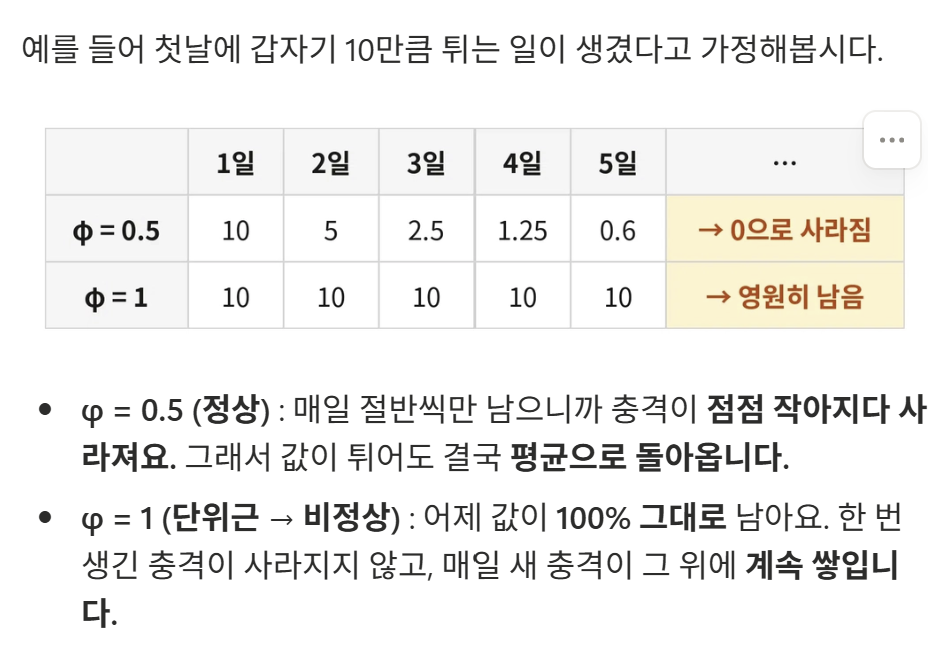

- 단위근 검정 방법
    - 대표적인 방법: **ADF 검정과 KPSS 검정**
    - ADF : 일단 ”비정상이다"라고 가정하고, 증거가 충분하면 ”정상"으로 판결
    - KPSS : 일단 ”정상이다"라고 가정하고, 증거가 충분하면 ”비정상"으로 판결

    - 두 모델 모두 정상이라고 나왔을 경우 -> 정상 시계열로 판단
    - 두 모델 모두 비정상이라고 나왔을 경우 -> 비정상 시계열
    - KPSS만 정상이라고 나왔을 경우 -> 추세 정상(Trend Stationary) 시계열일 가능성이 높음. <br> 단위근 때문에 랜덤하게 떠도는 게 아니라, 일정한 추세선을 따라 움직이면서 그 추세선 주위로는 안정적으로 오르내리는 경우 -> 추세 제거 후 재검정

## 3.4 정상성 확보를 위한 방법
1. 추세 제거 
    - 시계열이 장기적으로 한 방향으로 계속 오르거나 내려서, 시간에 따라 **평균이 변하는 경우**에 적용
    - **차분** : 오늘 값에서 어제를 빼서, 값 자체 대신 ”얼마나 변했나”를 보는 방법
    - 차분을 통해 정상성이 확보되는 이유 
        1. 추세가 사라짐
        2. 단위근이 사라짐 - 오늘 값에서 어제 값을 빼니까 “오늘 새로 생긴 일”만 남음 

2. 계절성 제거 
    - 시계열이 **일정한 주기마다 같은 모양을 반복**해서, 시점에 따라 평균이 달라지는 경우에 적용
    - **계절 차분** : 오늘 값에서 **한 주기(m) 전의 값**을 빼는 방법. ex) 작년 같은 때와 비교 

3. 분산 안정화
    - 시계열의 오르내리는 **폭이 시간이 지날수록 커지거나 작아져서**, 분산이 일정하지 않은 경우에 적용

    - **로그 변환** : 큰 값은 많이, 작은 값은 조금 줄기 때문에, 값이 커질수록 함께 커지던 변동 폭이 비슷한 크기로 정리 됨
        - 한계: 0이나 음수에는 쓸 수 없음, 모든 분산 변화를 해결하진 못함
        

# 4. 단변량 시계열 분석
1. 자기 회귀 모델 (AR)
    - **오늘 값을 자기 자신의 과거 값으로 설명**하는 모형<br>-> 시계열의 **자기 상관성**을 활용함

    - AR(p) 모형: 과거 p개 시점의 값 사용
    - AR(1) 모형: 바로 전 시점의 값 하나만 사용 (즉, p가 1일 때)<br>쉽게 말하면 **"오늘의 판매량" = 어제 판매량의 일부+오늘의 충격"**!
        - ”오늘 충격"은 오늘이 끝나야 알 수 있음. 그래서 아침에 예측할 때는 그 칸을 0으로 채워 두고, 저녁에 실제 값이 나오면 진짜 숫자로 바꿈.

- **충격이란**: 그 시점에 예측할 수 없었던 새로운 변화

2. 이동 평균 모델 (MA)
    - **오늘 값을 과거의 충격으로 설명**하는 모형
    - 예시: 아이스크림 가게로 말하면 **손님이 지난 방송을 보고 오는 가게**
    - MA(q) 모형: 과거 q개 시점의 충격 사용
    - MA(1) 모형: 바로 전 시점의 충격 하나만 사용(즉, q가 1일때)<br>쉽게 말하자면 **오늘 판매량 = 오늘 충격 + 어제 충격의 일부** 

**AR, MA 모델의 전제 조건**
1. 정상성
    - AR 모델의 정상성 조건
        1. AR(1)은 계수의 절댓값이 1보다 작아야 함.
            - 충격 100이 계수 0.8이면 80, 64로 줄어 평소로 돌아옴
        2. AR(p)는 아래 특성방정식의 모든 근의 절댓값이 1보다 커야 함.
            - AR(1)에서는 "계수의 절댓값이 1보다 작다"와 같은 말

    - MA 모델의 정상성 조건
        - 항상 정상임. 충격의 영향이 q일 뒤에 끝나기 때문! 

2. 가역성
    - 판매량 기록에서 **지난 충격을 거꾸로 계산해 낼 수 있는 성질**
    - 가역성을 확인하는 이유: **과거의 기록으로 충격을 왜곡 없이 안전하게 되돌려 계산할 수 있는지를 확인**해야 하기 때문

    - AR 모델의 가역성 조건
        - 항상 가역임. "오늘 충격 = 오늘 값 − 계수 × 어제 값"이라서 필요한 숫자가 전부 관측 가능한 값

    - MA 모델의 가역성 조건
        - MA(1)은 계수의 절댓값이 1보다 작아야함
        - MA(q)는 아래 특성방정식의 모든 근의 절댓값이 1보다 커야 함.

3. ARMA 모형
- 개념: AR과 MA를 한 식에 합친 모형. 오늘 값이 **과거 값**과 **과거 충격 양쪽의 영향**을 받음

- 예시

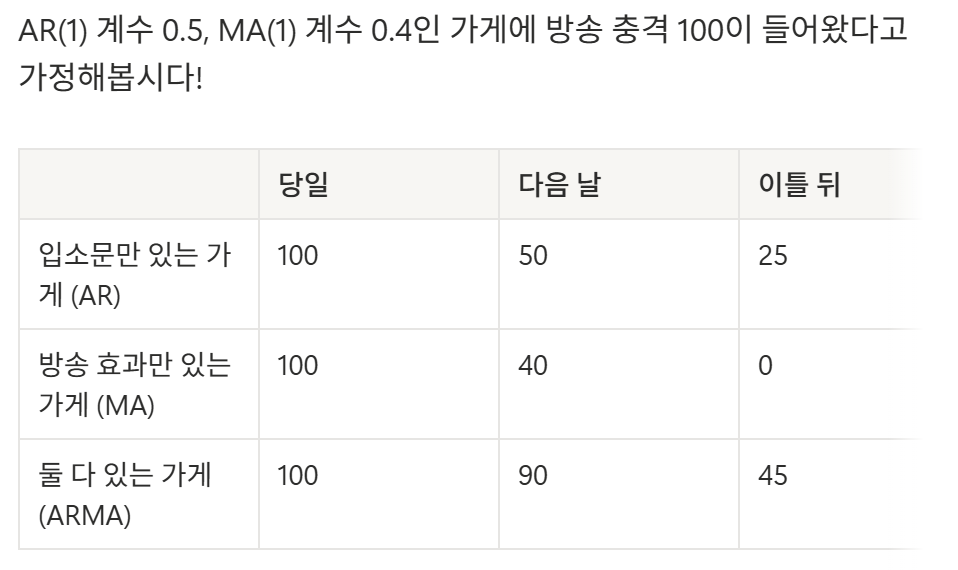

- 다음 날 90은 입소문을 듣고 온 50과 방송을 하루 늦게 본 40의 합임

- ARMA 모형의 특징
    - 같은 장부를 AR만으로 설명하려면 여러 시차를 넣어햐 하지만, ARMA는 더 적은 계수로 설명 가능
    - ARMA 모형도 마찬가지로 AR 부분이 정상성 조건을, MA 부분이 가역성 조건을 각각 만족해야 함.

**차수 결정 방법: 자기 상관 함수**
- ARMA(p,q) 모형에서 차수 p와 q는 ACF와 PACF 그래프에서 읽고 적절하게 선택함. 

- **자기 상관 계수(ACF)** -> ARMA(p,q)에서 q 결정
    - 오늘 값과 k시점 전 값이 얼마나 닮았는지를 상관계수로 잰 것
    $\rho(k)=\frac{Cov(y_t,\ y_{t-k})}{Var(y_t)}$
    - 특징
        - -1에서 1 사이의 값을 가짐. 시차 0에서는 항상 1임
        - 중간 날짜를 거쳐 온 영향까지 합쳐서 잼
        - 그래프의 점선 안쪽이면 0으로 봄

- **부분 자기 상관 계수** -> ARMA(p,q)에서 p 결정
    - 중간 시점들의 영향을 빼고, 오늘 값과 k시점 전 값이 직접 얼마나 닮았는지를 잰 것
    $\phi_{kk} = Corr(y_t,\ y_{t-k}\mid y_{t-1},\dots,y_{t-k+1})#
    - 특징: 시차 1에서는 중간 날짜가 없으므로 ACF와 값이 같음

- ACF와 PACF로 차수 및 모형 결정하기
    - **막대가 급격히 줄어들기 직전의 시차**를 고름

# 3. 정상성 판단
## 3.1 정상성이란
- 시계열 데이터의 **평균, 분산 등 통계적 특성**이 시간에 따라 일정한 수준으로 유지되는 것
	- **'시간에 상관없이' 일정한 성질을 띄고 있다**

- 정상성 여부에 따라 정상 시계열, 비정상 시계열로 나눠짐
- 통계 분석에서 정상성이 중요한 이유
	- **예측이 가능하다**: 과거의 패턴과 성질이 미래에도 똑같이 유지 될것이라 가정할 수 있기 때문에 통계모델링에 바로 적용하기 좋음

## 3.2 강한 정상성과 약한 정상성
- 강한 정상성: 완벽하지만 비현실적인 기준
- 강한 정상성 개념: 시간을 언제로 잡든, 데이터의 확률 분포 자체가 똑같은 상태
- 특징: 평균, 분산 뿐만 아니라 데이터의 왜도, 첨도 등 모든 통계적 특성이 일정
- 한계: 현실의 데이터는 잡음과 외부 요인이 항상 존재하기 때문에, 이런 상태는 거의 존재하지 않음

- 약한 정상성: 실무에서 쓰는 현실적인 기준
- 특징
	- 평균이 일정: 시간이 지나도 일정한 수준을 유지
	- 분산이 일정: 데이터의 오르내림 변동 폭이 일정한 수준을 유지
	- 자기공분산이 시차에만 의존: 데이터 간의 관계가 특정 시점이 아니라 시간의 간격에 의해서만 결정
		- 즉, 언제 측정하느냐가 중요한 것이 아닌, **얼마나 떨어졌느냐**만 중요하다는 것

## 3.3 정상성 판단하기
1. 시각적으로 정상성 판단하기
- 정상성을 띄는 시계열 데이터는 그래프를 봤을 때, **일정한 기준선(평균)을 중심으로 일정한 폭으로 진동**하는 형태를 보임

- 비정상 시계열의 대표적인 특징
	- 추세가 있는 경우: 시간에 따라 데이터가 지속적으로 상승하거나 하락(ex.주식 가격, 물가 상승률)
	- 계절성이 있는 경우: 1년 등의 특정 주기로 패턴이 반복됨 (ex. 월별 아이스크림 판매량)

- 추세가 뚜렷한 시계열을 정상 시계열로 변환하는 법
	- **차분** 한 결과로 해석 가능

2. 통계적 검정
- 필요성: 그래프만으로는 시각적으로 정상성 여부를 판단하기 어렵다. 이에 따른 수치적인 가설 검증이 필요함.
- 이때 대부분의 시계열 검정은 **단위근**이 있는지를 확인하는 과정을 거친다.
	- 단위근: 과거 충격이 영구적으로 누적되는 특성을 의미 - 대표적인 비정상성의 원인으로 존재
	- 시계열이 Random하게 움직이게 만들어 평균으로 회귀하지 않고, 분산이 시간에 따라 증가하며 예측이 어려워짐.

- 단위근으로 정상/비정상 시계열을 판단하는 과정
$$y_t = \alpha y_{t-1} + e_{t}$$ 
	- y  t ​   ,  𝑦 𝑡 − 1: 시계열의 관측값 
	- 𝛼  : AR(1) 계수 (자기회귀 계수) → 이 모델에서 특성방정식의 근(단위근)을 뜻함 
	- 𝑒 𝑡  : 백색 잡음. 외부 충격을 뜻함.

- 𝛼=0일때 (완전한 백색잡음)
	- 과거 값 𝑦 𝑡 − 1의 영향을 **전혀 받지 않음** 
	- 오직 외부 충격(오차항 𝑒𝑡)만으로 시계열이 생성됨
	- 오늘의 값은 어제와 아무 관련이 없고, 오로지 외부 요인에 의해 무작위로 결정된다<br>
→ 완전한 정상성을 가짐

- ∣α∣<1일때 (정상 시계열)
	- 현재 값이 이전 값의 영향을 받지만, 시간이 지날수록 과거 충격의 영향은 **점점 줄어듦(희석됨)**
	- 외부 충격의 영향이 시간이 지날수록 점차 사라지고 시계열은 평균 수준으로 돌아온다!<br>
→ 정상 시계열로 간주 

- α=1일때 (비정상 시계열), 단위근이 있음
	- yt는 지금까지의 오차의 누적과 같음
	- 외부 충격으로 인한 변동이 계속 유지되어 한 번 충격을 받으면 원상태로 돌아가지 못함
	- 시계열이 일정한 분포나 상태로 수렴하지 않음 → 예측 불가능

- 단위근 검정 방법
	- ADF
		- "이 시계열이 비정상이 아님을 증명하자" 는 관점에서 출발
		- 시계열이 과거 값에 얼마나 의존하는지를 측정
		- 과거 값의 영향이 시간이 지남에 따라 점점 사라지면 정상 시계열, <br>누적되어 사라지지 않으면 단위근이 존재하는 비정상 시계열로 판단
	- KPSS
		- "이 시계열이 정상임을 반증하자"는 관점에서 출발
		- ADF의 검정력이 낮다는 한계를 보완하기 위해 함께 사용
		- KPSS는 시계열이 일정한 평균 수준을 유지하는지를 측정
		- 평균이 시간에 따라 흔들리지 않으면 정상, 평균 자체가 계속 변하고 있으면 비정상으로 판단

## 3.4 정상성 확보를 위한 여러가지 방법들
1. 추세 제거
	- 시계열이 지속적으로 증가하거나 감소할 때 적용
	- **차분**: 연이은 관측값들의 차이를 계산하는 것

2. 계절성 제거
	- 시계열이 주기적인 패턴을 가질 때 적용
	- **계절 차분** t시점의 𝑦값에서 t-m시점의 y값을 빼는 것 (m: 주기의 길이)

3. 분산 안정화
	- 시계열의 변동 폭이 점점 커지거나 작아질 때 적용
	- **로그변환**: 분산의 정상성 확보하기 위한 방법

# 4. 단변량 시계열 분석
## 4.1 안정적 시계열 분석
1. 자기 회귀 모델(Autoregressive Model, AR)
<br>: 과거의 ‘자기 자신 데이터(순위)’가 미래 값을 설명해줄 것이라고 가정하는 것이 자기 회귀

- 자귀회귀: 
과거 자신의 값들을 독립변수(x)로 삼아 현재 값(y)을 예측하는 회귀
<br>→ 시계열 데이터의 ‘자기상관성’을 활용 

- $$AR(p):  y_{t}=c +\phi _1y_{t-1}+\phi_2y_{t-2}+...+\phi _py_{t-p}+\varepsilon _t$$
	- p차 자기 회귀 모형
	- 과거 p개 시점의 데이터의 선형 조합을 이용해 예측하는 모델

2. 이동 평균 모델(Moving Average, MA)
- 앞서 나온 이동평균과 완전히 다른 개념
- **어제의 충격이 오늘의 결과에 영향**을 준다고 가정하는 것이 바로 이동 평균의 핵심

- 이동평균모델:  과거 시점의 잔차(ε)를 독립변수로 삼아 현재 값을 예측하는 모델<br>
→ 과거의 잘못 예측한 것(예측 오차, 충격)을 현재 시점에 반영

- $$MA(q): y_t = \mu +\varepsilon _t+ \theta _1\varepsilon_{t-1}+\theta_2\varepsilon_{t-2}+...+\theta_q\varepsilon_{t-q}$$
	- q차 이동 평균 모형
	- **과거 q개의 예측 오차**의 **선형 결합**으로 예측하는 모델

#### AR, MA 모델의 전제 조건
1. 정상성
	- AR과 MA 모형은 안정적 시계열 분석으로 확률적 안정성을 전제로 추정<br>
→ 모델 구조도 정상성을 만족해야 함
	- AR 모형의 정상성 조건: 모든 해(z) 의 절대값>1
	- MA 모형의 정상성 조건: 잔차(<=> 백색잡음)들은 정상성을 이미 만족하기 때문에, <br>잔차들의 조합으로 이뤄진 MA 모형도 항상 정상성 만족

2. 가역성
	- 가역성: MA 모형을 AR(∞) 형태로 재표현할 수 있는지 여부
	- 필요성: MA 모형에서는 현재 시점의 값을 과거 시점의 오차항 ε으로 예측 <br>→ 문제 : 오차항은 직접 관찰이 불가능<br> → 오차항(ε )도 관측 가능한 과거값( 𝑦 𝑡 − 𝑛 )으로 표현할 수 있어야 안정적
	- AR 모형의 가역성 만족 조건?
		- AR 모형은 처음부터 AR형태로 표현되어 있기 때문에 가역성 체크할 필요 X
	- MA모형의 가역성 만족 조건: 모든 해(z)의 절대값>1

#### ARMA 모형
- AR(p) 모형과 MA(q) 모형을 결합한 모형 
- 과거 p개의 관측값 + 과거 q개의 오차를  활용해서 예측하는 방법
- 조건: AR(p) 모형의 정상성 + MA(q) 모형의 가역성 → 이 둘의 조건 모두 만족해야 함

#### 차수 결정 방법: 자기 상관 함수
- 두 그래프를 통해 현재 값이 과거 값과 어떤 관계가 있는지 파악하고 이를 통해 AR, MA, ARMA의 적절한 차수(p, q)를 결정

- 자기 상관 계수(Auto Correlation Function, ACF)
	- ARMA(p, q)모형에서 사용할 q개의 오차 결정 방법
	- 두 시점 사이의 상관 관계 파악 (간접 영향까지 모두 파악)

- 부분 자기 상관 계수 (Partial Autocorrelation Function, PACF)
	- ARMA(p, q) 모형에서 사용할 p개의 시점 결정 방법
	- 두 시점 사이의 직접적인 영향만 파악

## 4.2 불안정 시계열 분석
- 불안정 시계열 모델은 안정적 시계열 모델(ARMA)에 정상성 확보 과정(차분, 계절성 차분)이 추가된 형태

1. ARIMA (Autoregressive Integrated Moving Average)
$$ ARMA(p, q) + \text{차분} \rightarrow ARIMA(p,d,q) $$

- ARIMA 모형의 특수한 경우
1. 백색잡음: ARIMA(0,0,0)
2. 자기회귀: ARIMA(p,0,0) ⇔ AR(p)
3. 이동평균: ARIMA(0, 0, q) ⇔ MA(q)
4. 랜덤워크: 상수가 없는 ARIMA(0,1,0)
5. 표류를 포함하는 랜덤워크: 상수가 있는 ARIMA(0,1,0)

2. SARIMA (Seasonal ARIMA)
- 시계열 데이터의 계절성을 처리할 수 있는 모델
- ARIMA 모델에 계절성 변동을 반영한 모델

- 하이퍼파라미터
	- (p,d,q): 비계절 ARIMA 파라미터
		- p → AR의 차수
		- d → 차분의 정도
		- q → MA의 차수
	- (P,D,Q): 계절 ARIMA 파라미터
		- 𝑃→ 계절성 AR의 차수
		- D → 계절성 차분의 정도
		- Q → 계절성 MA의 차수
	- m: 계절성 주기의 길이

# 5. 다변량 시계열 분석
## 5.1 VAR(Vector Autoregression)

- 핵심 아이디어: 자신의 과거 값과 다른 변수들의 과거 값을 함께 사용하여 미래를 예측하는 모델
- 단변량 VAR: X는 자기 자신의 과거만 사용
- 다변량 VAR:  X와 Y가 서로의 과거를 함께 사용

- VAR 모델을 활용한 분석방법
	1. 충격 반응 함수: 한 변수의 충격이 다른 변수에 미치는 영향을 시간 흐름에 따라 분석
	2. 예측오차 분산 분해: 예측 오차에 각 변수가 얼마나 기여하는지 분석

# 6. 딥러닝을 활용한 시계열 분석
- 등장 배경: 전통 통계 모델의 한계

1. 순환 신경망(RNN 계열)
	- RNN/LSTM/GRU

- 적합한 경우:
	- 순차적 패턴이 중요한 시계열 데이터
	- 과거 정보가 미래 예측에 영향을 주는 문제
	- 시계열 길이와 목적에 따라 모델 선택 가능

- 부적합한 경우
	- 매우 긴 시계열(수천~수만 step)에서는 학습이 어려울 수 있음
	- 병렬 처리 효율이 낮음
	- Transformer 계열 대비 학습 속도가 느린 편

2. Transformer 계열
1. Informer(장기 예측 특화)
	- 특징: 불필요한 연산을 줄여 계산 복잡도를 대폭 낮춘 모델
	- 매우 긴 시계열 데이터 처리에 강력함

2. Autoformer(주기성 포착 특화)
	- 특징: 시계열의 전통적 기법인 '요소 분해(추세/계절성)' 개념을 딥러닝 구조에 직접 결합한 모델
	- 연간 계절성 등 주기 패턴이 뚜렷하게 나타나는 판매량 예측에 압도적인 성능을 보임

3. TFT(Temporal Fusion Transformer - 실무 활용도 1위)
	- 특징:  과거 데이터뿐만 아니라 다양한 외부 변수(날씨, 휴일 유무 등)를 섞어서 예측할 수 있는 다목적 아키텍처
	- 어떤 변수가 예측에 가장 중요했는지 어텐션 스코어를 통한 해석이 가능해, 설명력이 중요한 유통/비즈니스 수요 예측에 가장 많이 쓰임

3. Foundation Model
- 거대한 데이터로 사전 학습하여 다양한 문제를 해결할 수 있는 범용 모델
- 특징
	- 특정 문제에 적용 안됨
	- 범용적
	- 사전 학습 후 파인 튜닝으로 특화